# Pascal NF-generated background: time stability

This notebook repeats the DC4 time-stability diagnostic from notebook 03 on the saved three-month sample generated with Pascal Janowski's time-dependent normalizing-flow background model. It asks one question: after applying the documented SAA exclusion and normalizing away the total event count, how much does the generated shape in $(E_m, \phi, \psi, \chi)$ change with time?

Scope boundaries:

- The only event input is `nf_background_3months.hdf5`.
- The HDF5 file is opened read-only and is never modified.
- No model is loaded, sampled, evaluated, retrained, corrected, or smoothed here.
- The only event selection is the same orientation-file SAA exclusion used in notebook 03.
- Raw counts/rates and independently normalized shapes are examined separately.
- Histogram bins are diagnostic and exactly match notebook 03; they are not a new background model.
- This notebook analyzes the NF sample by itself. A combined DC4-versus-NF figure is intentionally deferred.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup

In [2]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
background_path = Path("../data/nf_background_3months.hdf5")
orientation_path = Path("../data/DC4_orientation.ori")
assert background_path.exists() and orientation_path.exists()

## 2. Inspect the saved NF-generated event file

The file is inspected directly with `h5py` because it contains about 169 million events. Only dataset metadata are read in this cell; the event arrays remain on disk.

In [4]:
with h5py.File(background_path, "r") as file:
    datasets = {name: (item.shape, str(item.dtype)) for name, item in file.items()}
    attributes = dict(file.attrs)
    event_count = len(file["TimeTags"])
print(f"Events: {event_count:,}")
datasets, attributes

Events: 168,635,152


({'Chi local': ((168635152,), 'float32'),
  'Energies': ((168635152,), 'float32'),
  'Phi': ((168635152,), 'float32'),
  'Psi local': ((168635152,), 'float32'),
  'TimeTags': ((168635152,), 'float64')},
 {'completed_events': np.int64(168635152),
  'target_events': np.int64(168635152),
  'time_rng_state': '{"bit_generator": "PCG64", "state": {"state": 10980460574906598334897216753136152300, "inc": 25065611243303971628957076795638243391}, "has_uint32": 0, "uinteger": 0}'})

### Event mapping and provenance

The native datasets provide `TimeTags`, `Energies`, `Phi`, `Psi local`, and `Chi local`, matching the variables used in notebook 03. `TimeTags` are Unix seconds; `Energies` are $E_m$ in keV; all three stored angles are in radians. As in notebook 03, the diagnostic uses the stored `Psi local` colatitude directly so that the histogram definition is identical.

The generation script sampled event times from Pascal's learned rate multiplied by the orientation livetime and then sampled the CDS density conditioned on those times. Zero-livetime intervals should therefore have zero sampling probability. This is a statement about how the saved sample was generated, not a substitute for verification: the next sections independently reapply the same orientation-based SAA selection and count any rejected rows.

## 3. Reproduce the documented SAA selection

COSIpy's [`cut_SAA_events`](https://github.com/cositools/cosipy/blob/2cc83ad5176338cbacddb2205db2e31b9b7f8b15/cosipy/data_io/UnBinnedData.py#L825-L917) constructs bad intervals from entries with zero livetime in the orientation file. The corresponding [orientation parser](https://github.com/cositools/cosipy/blob/2cc83ad5176338cbacddb2205db2e31b9b7f8b15/cosipy/spacecraftfile/spacecraft_file.py#L395-L499) defines the final `.ori` column as the accumulated livetime up to the following timestamp.

Events are assigned to half-open orientation intervals $[t_i,t_{i+1})$ and retained only when that interval has positive livetime. This is exactly the SAA logic used in notebook 03; no SAA boundary is inferred from the NF events or their rate.

In [5]:
orientation = np.loadtxt(orientation_path, skiprows=1, comments="EN", usecols=range(1, 10))
orientation_times = orientation[:, 0]
livetimes = orientation[:-1, 8]
interval_durations = np.diff(orientation_times)

In [6]:
excluded = livetimes == 0
start_index = np.flatnonzero(excluded & np.r_[True, ~excluded[:-1]])
stop_index = np.flatnonzero(excluded & np.r_[~excluded[1:], True]) + 1
saa_starts, saa_stops = orientation_times[start_index], orientation_times[stop_index]

In [7]:
saa_durations = saa_stops - saa_starts
print(f"Orientation intervals: {len(livetimes):,}; SAA blocks: {len(saa_starts):,}")
print(f"SAA duration [s], min/median/max: {saa_durations.min():.0f}/{np.median(saa_durations):.0f}/{saa_durations.max():.0f}")
print(f"Accepted livetime fraction: {livetimes.sum() / interval_durations.sum():.3f}")

Orientation intervals: 531,997; SAA blocks: 1,300
SAA duration [s], min/median/max: 525/1080/1125
Accepted livetime fraction: 0.825


## 4. Define the temporal comparisons

There is no orbit identifier in either input. Rather than invent orbit boundaries, `time_interval_days` controls consecutive wall-clock intervals. Its default remains **7 days**, exactly as in notebook 03. You may change this single value and rerun from this cell onward to inspect another duration. The final shorter interval is retained and its actual duration and livetime are reported; no events are removed to force equal durations.

The second comparison also matches notebook 03: events in the first 10 minutes after each documented SAA block are compared with those in the final 10 minutes before the next block. This follows the diagnostic used in Section 3.6.1 and Figure 3.17 of [Pascal Janowski's thesis](https://cms.zdv.uni-mainz.de/fb08-xenon-physik/wp-content/uploads/sites/107/2026/03/oberlack-group-thesis_2025_MSc_Janowski-Pascal.pdf).

In [8]:
time_interval_days = 7.0
time_step = time_interval_days * 86400
time_edges = np.arange(orientation_times[0], orientation_times[-1], time_step)
time_edges = np.append(time_edges, orientation_times[-1])
number_time_groups = len(time_edges) - 1
group_days = np.diff(time_edges) / 86400
print(f"Time groups: {number_time_groups}; requested duration: {time_interval_days:g} days")
print(f"Actual durations [days]: min={group_days.min():.3f}, max={group_days.max():.3f}")

Time groups: 14; requested duration: 7 days
Actual durations [days]: min=1.361, max=7.000


In [9]:
group_livetime = np.zeros(number_time_groups)
for group in range(number_time_groups):
    overlap = np.maximum(0, np.minimum(orientation_times[1:], time_edges[group + 1]) - np.maximum(orientation_times[:-1], time_edges[group]))
    group_livetime[group] = np.sum(overlap * livetimes / interval_durations)

## 5. Diagnostic CDS histograms

The following edges are copied unchanged from notebook 03: 120 logarithmic energy bins from 100 to 10,000 keV, 60 bins each for `Phi` and `Psi`, and 120 bins for `Chi`, over their full stored angular domains.

The separate coarse 4D table also matches notebook 03: $10\times6\times6\times12=4320$ cells. It checks correlations that marginal projections can miss. It is only a diagnostic contingency table, not $P(E_m,\phi,\psi,\chi)$ and not a learned model.

In [10]:
projection_edges = {
    "Energy": np.geomspace(100, 10_000, 121),
    "Phi": np.linspace(0, np.pi, 61),
    "Psi": np.linspace(0, np.pi, 61),
    "Chi": np.linspace(0, 2 * np.pi, 121),
}
projection_columns = {"Energy": "Energies", "Phi": "Phi", "Psi": "Psi local", "Chi": "Chi local"}

In [11]:
joint_edges = [np.geomspace(100, 10_000, 11), np.linspace(0, np.pi, 7),
               np.linspace(0, np.pi, 7), np.linspace(0, 2 * np.pi, 13)]
joint_shape = tuple(len(edges) - 1 for edges in joint_edges)
print(f"Coarse 4D cells: {np.prod(joint_shape):,}")

Coarse 4D cells: 4,320


In [12]:
group_counts = {name: np.zeros((number_time_groups, len(edges) - 1), dtype=np.int64) for name, edges in projection_edges.items()}
phase_counts = {name: np.zeros((2, len(edges) - 1), dtype=np.int64) for name, edges in projection_edges.items()}
joint_counts = np.zeros((number_time_groups, np.prod(joint_shape)), dtype=np.int64)
events_per_group, events_per_phase = np.zeros(number_time_groups, dtype=np.int64), np.zeros(2, dtype=np.int64)

### One read-only, chunked pass through the events

Each saved event is mapped to its orientation interval. A row is accepted only when it lies inside the orientation coverage and that interval has positive livetime. Events outside the orientation coverage and events inside zero-livetime intervals are counted separately, so the SAA status of the generated sample is explicit. The HDF5 rows are not assumed to be time ordered.

No event values are changed. Counts outside the fixed notebook-03 histogram domains are reported explicitly rather than clipped into an edge bin. Normalization occurs later on histogram copies only.

In [13]:
saa_rejected_events, outside_orientation_events = 0, 0
group_axis_edges = np.arange(number_time_groups + 1) - 0.5
with h5py.File(background_path, "r") as events:
    for start in range(0, event_count, 1_000_000):
        stop = min(start + 1_000_000, event_count)
        times = np.asarray(events["TimeTags"][start:stop])
        interval = np.searchsorted(orientation_times, times, side="right") - 1
        in_range = (interval >= 0) & (interval < len(livetimes))
        accepted = np.zeros(len(times), dtype=bool)
        accepted[in_range] = livetimes[interval[in_range]] > 0
        outside_orientation_events += np.count_nonzero(~in_range)
        saa_rejected_events += np.count_nonzero(in_range & ~accepted)
        group = np.searchsorted(time_edges, times, side="right") - 1
        keep = accepted & (group >= 0) & (group < number_time_groups)
        kept_group = group[keep]
        events_per_group += np.bincount(kept_group, minlength=number_time_groups)

        previous_exit = np.searchsorted(saa_stops, times, side="right") - 1
        after = accepted & (previous_exit >= 0)
        after[after] &= times[after] - saa_stops[previous_exit[after]] < 600
        next_entry = np.searchsorted(saa_starts, times, side="left")
        before = accepted & (next_entry < len(saa_starts))
        before[before] &= saa_starts[next_entry[before]] - times[before] < 600
        events_per_phase += [np.count_nonzero(after), np.count_nonzero(before)]

        values_by_axis = []
        for name, column in projection_columns.items():
            values = np.asarray(events[column][start:stop])
            values_by_axis.append(values)
            group_counts[name] += np.histogram2d(kept_group, values[keep], bins=(group_axis_edges, projection_edges[name]))[0].astype(np.int64)
            phase_counts[name][0] += np.histogram(values[after], bins=projection_edges[name])[0]
            phase_counts[name][1] += np.histogram(values[before], bins=projection_edges[name])[0]

        joint_bins, joint_ranges = [], []
        for edges, values in zip(joint_edges, values_by_axis):
            kept_values = values[keep]
            joint_ranges.append((kept_values >= edges[0]) & (kept_values <= edges[-1]))
            bins = np.searchsorted(edges, kept_values, side="right") - 1
            joint_bins.append(np.clip(bins, 0, len(edges) - 2))
        valid_joint = np.logical_and.reduce(joint_ranges)
        flat_joint = np.ravel_multi_index(tuple(bins[valid_joint] for bins in joint_bins), joint_shape)
        flat_grouped = kept_group[valid_joint] * joint_counts.shape[1] + flat_joint
        joint_counts += np.bincount(flat_grouped, minlength=joint_counts.size).reshape(joint_counts.shape)

In [14]:
accepted_events = events_per_group.sum()
rejected_events = saa_rejected_events + outside_orientation_events
print(f"Accepted events: {accepted_events:,}")
print(f"Rejected in zero-livetime intervals: {saa_rejected_events:,}")
print(f"Outside orientation coverage: {outside_orientation_events:,}")
assert accepted_events + rejected_events == event_count
histogram_overflow = pd.Series({name: accepted_events - counts.sum() for name, counts in group_counts.items()})
histogram_overflow.loc["Joint 4D"] = accepted_events - joint_counts.sum()
print("Accepted events outside each fixed histogram domain:")
print(histogram_overflow.astype(np.int64).to_string())
assert (histogram_overflow >= 0).all()

Accepted events: 168,635,152
Rejected in zero-livetime intervals: 0
Outside orientation coverage: 0
Accepted events outside each fixed histogram domain:
Energy      0
Phi         0
Psi         2
Chi         5
Joint 4D    7


## 6. Raw amplitude: counts and rate

This section deliberately does not normalize event counts. It describes the amplitude generated by Pascal's learned rate model after the common SAA selection. These plots are not evidence about CDS-shape stability.

In [15]:
amplitude = pd.DataFrame({
    "midpoint_day": ((time_edges[:-1] + time_edges[1:]) / 2 - time_edges[0]) / 86400,
    "livetime_days": group_livetime / 86400,
    "raw_events": events_per_group,
    "rate_per_second": events_per_group / group_livetime,
})
amplitude

,midpoint_day,livetime_days,raw_events,rate_per_second
0,3.500000,5.786285,12523561,25.050379
1,10.500000,5.774132,12720424,25.497708
2,17.500000,5.784722,12791376,25.592989
3,24.500000,5.769792,12780052,25.636501
4,31.500000,5.781250,12811219,25.648086
5,38.500000,5.769618,12799213,25.675710
6,45.500000,5.776736,12813215,25.672126
7,52.500000,5.763889,12796915,25.696616
8,59.500000,5.775347,12831637,25.715219
9,66.500000,5.760069,12804736,25.729371


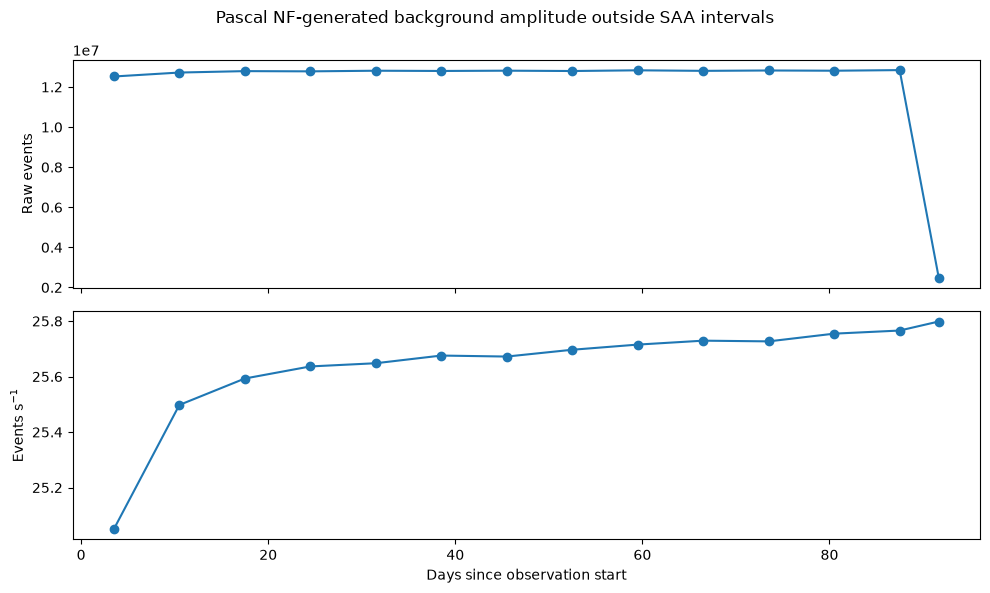

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(amplitude.midpoint_day, amplitude.raw_events, marker="o")
axes[1].plot(amplitude.midpoint_day, amplitude.rate_per_second, marker="o")
axes[0].set_ylabel("Raw events")
axes[1].set(xlabel="Days since observation start", ylabel="Events s$^{-1}$")
fig.suptitle("Pascal NF-generated background amplitude outside SAA intervals")
fig.tight_layout()

## 7. Independently normalized CDS projections

Every time-group histogram is divided by its own event total and bin width. Consequently, these plots compare shape rather than amplitude. The underlying events and stored count histograms remain unchanged.

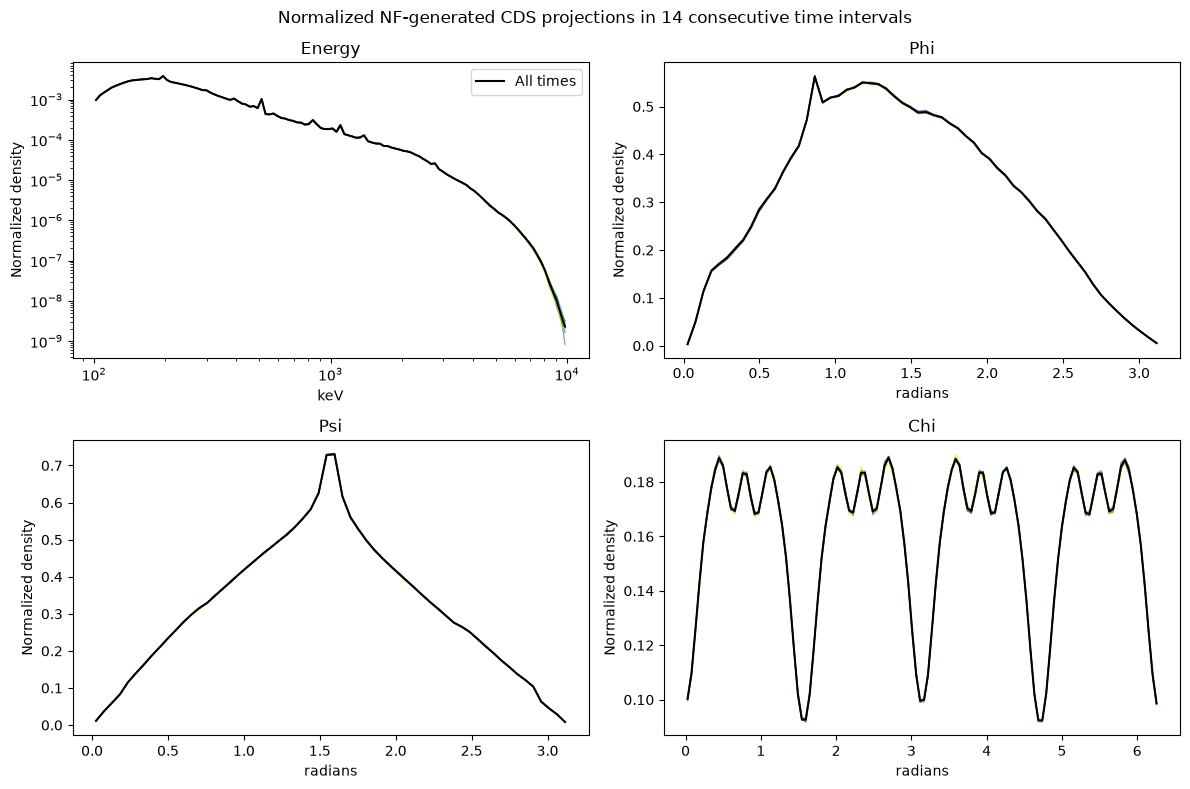

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0, 1, number_time_groups))
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for group, color in enumerate(colors):
        density = group_counts[name][group] / group_counts[name][group].sum() / np.diff(edges)
        ax.plot(centers, density, color=color, alpha=0.65, linewidth=0.8)
    pooled = group_counts[name].sum(axis=0) / group_counts[name].sum() / np.diff(edges)
    ax.plot(centers, pooled, color="black", linewidth=1.5, label="All times")
    ax.set(title=name, xlabel="keV" if name == "Energy" else "radians", ylabel="Normalized density")
    if name == "Energy":
        ax.set(xscale="log", yscale="log")
axes[0, 0].legend()
fig.suptitle(f"Normalized NF-generated CDS projections in {number_time_groups} consecutive time intervals")
fig.tight_layout()

### Quantify shape changes

Each time interval is compared with a reference made from all *other* intervals. Total variation distance (TVD) measures the absolute redistribution of probability. `noise_TVD` is the same analytic Gaussian multinomial counting-noise scale used in notebook 03. Every histogram cell is retained.

TVD measures the size of a normalized-shape change; `TVD/noise_TVD` indicates whether counting noise alone is a plausible explanation. A large ratio does not by itself imply a large practical effect.

In [18]:
def shape_metrics(counts):
    pooled = counts.sum(axis=0)
    rows = []
    for observed in counts:
        reference_counts = pooled - observed
        reference = reference_counts / reference_counts.sum()
        probability = observed / observed.sum()
        tvd = 0.5 * np.abs(probability - reference).sum()
        variance = reference * (1 - reference) * (1 / observed.sum() + 1 / reference_counts.sum())
        noise_tvd = 0.5 * np.sqrt(2 / np.pi) * np.sqrt(variance).sum()
        rows.append((tvd, noise_tvd, tvd / noise_tvd))
    return pd.DataFrame(rows, columns=["TVD", "noise_TVD", "TVD/noise_TVD"])

In [19]:
metric_tables = {name: shape_metrics(counts) for name, counts in group_counts.items()}
metric_tables["Joint 4D"] = shape_metrics(joint_counts)
long_term_summary = pd.DataFrame({name: {
    "median_TVD": table["TVD"].median(), "max_TVD": table["TVD"].max(),
    "median_TVD/noise": table["TVD/noise_TVD"].median(), "max_TVD/noise": table["TVD/noise_TVD"].max(),
} for name, table in metric_tables.items()}).T
long_term_summary

,median_TVD,max_TVD,median_TVD/noise,max_TVD/noise
Energy,0.002033,0.005827,1.684460,5.283566
Phi,0.000998,0.002181,1.147232,2.573947
Psi,0.000929,0.001829,1.072353,1.300770
Chi,0.001262,0.002818,1.001660,1.146811
Joint 4D,0.006066,0.012966,1.035599,1.414457


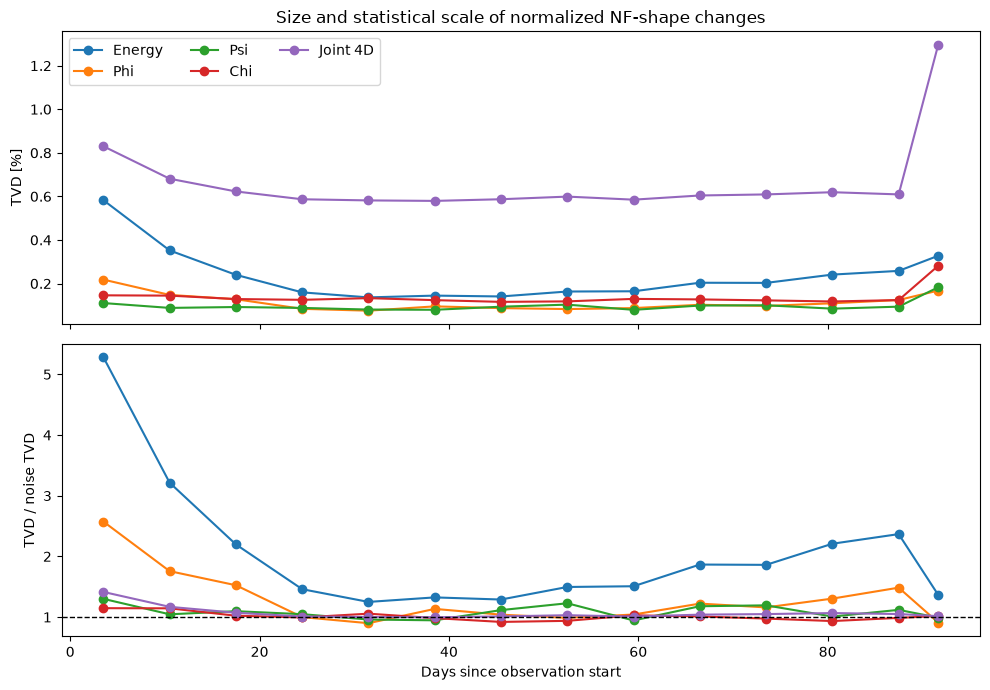

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for name, table in metric_tables.items():
    axes[0].plot(amplitude.midpoint_day, 100 * table["TVD"], marker="o", label=name)
    axes[1].plot(amplitude.midpoint_day, table["TVD/noise_TVD"], marker="o", label=name)
axes[1].axhline(1, color="black", linestyle="--", linewidth=1, label="Counting-noise scale")
axes[0].set(ylabel="TVD [%]", title="Size and statistical scale of normalized NF-shape changes")
axes[1].set(xlabel="Days since observation start", ylabel="TVD / noise TVD")
axes[0].legend(ncol=3)
fig.tight_layout()

### Where the normalized shape changes

For each time interval, the reference is formed from all other intervals. The heatmaps show $100\,(p_{i,b}-p_{\mathrm{ref},b})$: the difference in normalized probability for CDS bin $b$, expressed in percentage points. This is calculated from histogram copies only. It is not a model residual, and no event or histogram bin is removed.

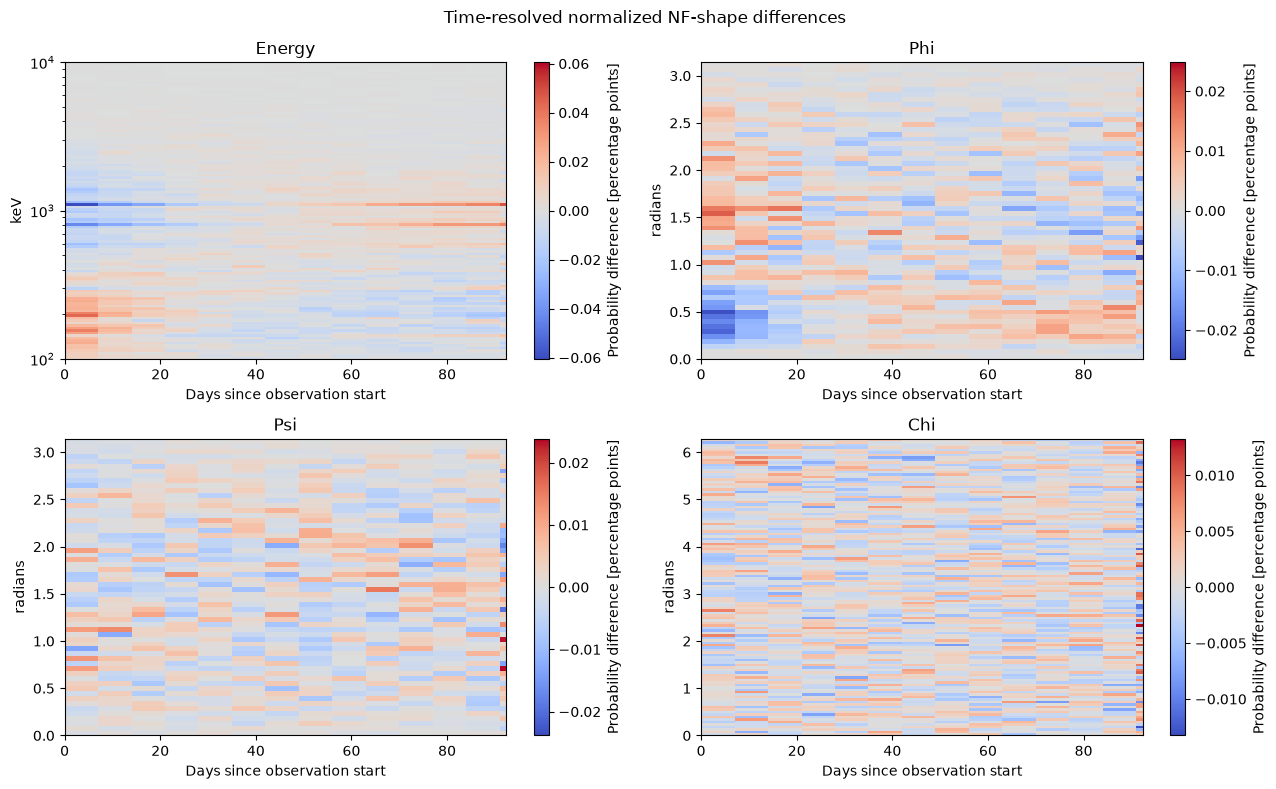

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
elapsed_edges = (time_edges - time_edges[0]) / 86400
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    counts = group_counts[name]
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    other_counts = counts.sum(axis=0, keepdims=True) - counts
    references = other_counts / other_counts.sum(axis=1, keepdims=True)
    difference = 100 * (probabilities - references)
    limit = np.max(np.abs(difference))
    image = ax.pcolormesh(elapsed_edges, edges, difference.T, shading="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set(title=name, xlabel="Days since observation start", ylabel="keV" if name == "Energy" else "radians")
    if name == "Energy":
        ax.set_yscale("log")
    fig.colorbar(image, ax=ax, label="Probability difference [percentage points]")
fig.suptitle("Time-resolved normalized NF-shape differences")
fig.tight_layout()

## 8. Shape before and after SAA intervals

The two rows are normalized independently, removing their different event totals. The comparison uses only accepted events in the same 10-minute windows as notebook 03.

In [22]:
phase_summary = {}
for name, counts in phase_counts.items():
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    tvd = 0.5 * np.abs(probabilities[0] - probabilities[1]).sum()
    pooled = counts.sum(axis=0) / counts.sum()
    variance = pooled * (1 - pooled) * (1 / counts[0].sum() + 1 / counts[1].sum())
    noise_tvd = 0.5 * np.sqrt(2 / np.pi) * np.sqrt(variance).sum()
    phase_summary[name] = (tvd, noise_tvd, tvd / noise_tvd)
phase_summary_table = pd.DataFrame(phase_summary, index=["TVD", "noise_TVD", "TVD/noise_TVD"]).T
print(f"Events after/before SAA windows: {events_per_phase[0]:,}/{events_per_phase[1]:,}")
phase_summary_table

Events after/before SAA windows: 21,329,753/20,409,308


,TVD,noise_TVD,TVD/noise_TVD
Energy,0.005828,0.001165,5.002880
Phi,0.002613,0.000894,2.924427
Psi,0.002697,0.000895,3.012605
Chi,0.001804,0.001341,1.344968


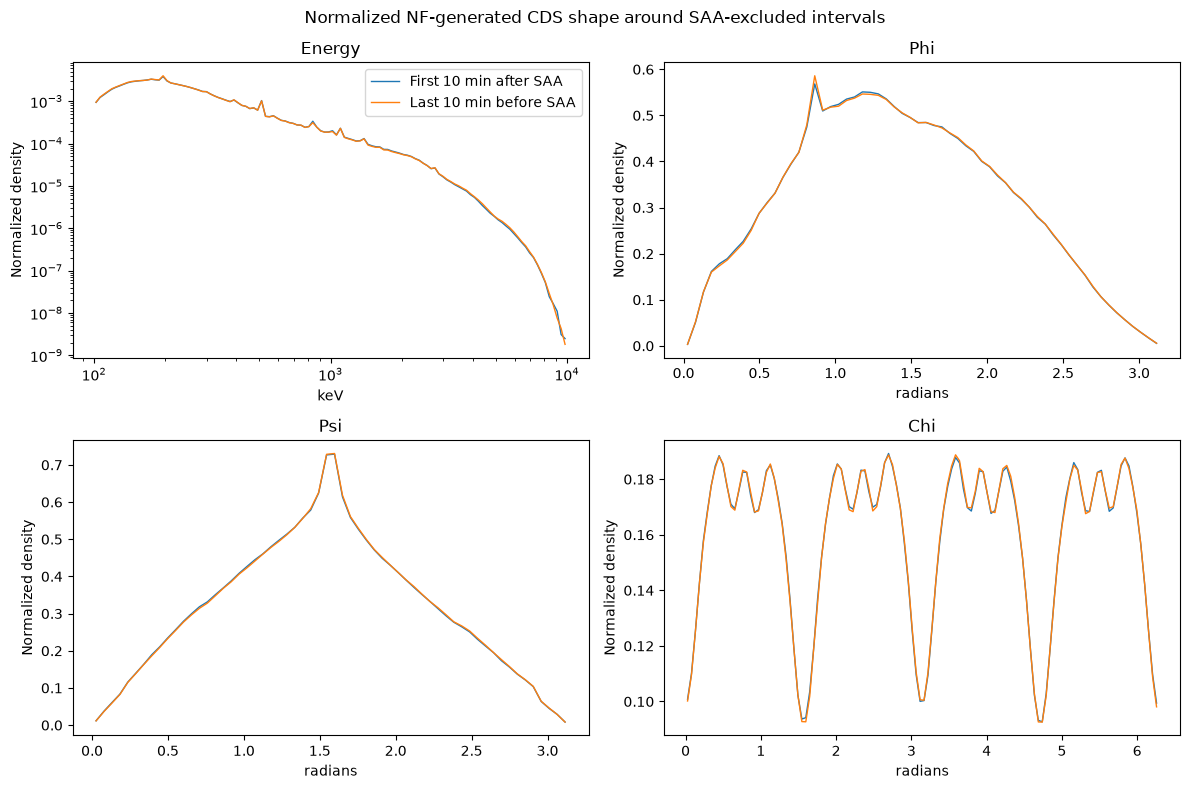

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, edges) in zip(axes.flat, projection_edges.items()):
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for index, label in enumerate(["First 10 min after SAA", "Last 10 min before SAA"]):
        density = phase_counts[name][index] / phase_counts[name][index].sum() / np.diff(edges)
        ax.plot(centers, density, label=label, linewidth=1)
    ax.set(title=name, xlabel="keV" if name == "Energy" else "radians", ylabel="Normalized density")
    if name == "Energy":
        ax.set(xscale="log", yscale="log")
axes[0, 0].legend()
fig.suptitle("Normalized NF-generated CDS shape around SAA-excluded intervals")
fig.tight_layout()

## 9. Interpretation and comparison boundary

### SAA audit and amplitude

All 168,635,152 generated events lie inside the orientation coverage, and none lie in a zero-livetime interval. The NF sample is therefore already SAA-filtered by its rate-times-livetime generation procedure; the notebook nevertheless reapplies and verifies the common DC4 selection. Seven angular values lie one `float32` step above a nominal histogram endpoint (two in `Psi`, five in `Chi`). They are reported rather than changed or silently assigned to an edge bin.

The generated rate increases from about 25.05 to 25.80 events/s across the three months. This is an amplitude result and is not used as evidence for or against shape stability.

### NF-only shape result

After independent normalization, the NF-generated shape is **not strictly time independent at the statistical precision of this sample**:

- Energy has the strongest resolved long-term marginal change: maximum TVD $=0.00583$, or 5.28 times the analytic counting-noise scale.
- `Phi` reaches TVD $=0.00218$ and 2.57 times the noise scale. Long-term `Psi` and `Chi` changes remain much closer to counting noise, with maximum ratios 1.30 and 1.15.
- The coarse joint 4D table reaches TVD $=0.01297$ and 1.41 times its noise scale. The absolute joint redistribution is about 1.3%, although its finer contingency table also carries more counting noise.
- In the 10-minute before/after-SAA comparison, the TVD/noise ratios are 5.00 for energy, 2.92 for `Phi`, 3.01 for `Psi`, and 1.34 for `Chi`. The generated density therefore retains a measurable dependence on time relative to SAA passages, even though no SAA events themselves are present.

### Direct relation to notebook 03

No combined figure is made here. Reading the like-for-like tables from notebook 03, the main pattern is reproduced: energy is the strongest resolved marginal variation and `Phi` is next. The NF maximum TVDs are somewhat smaller than DC4 for energy (0.00583 versus 0.00840) and `Phi` (0.00218 versus 0.00257), while the joint 4D maxima are nearly identical (0.01297 versus 0.01285). The before/after-SAA TVDs are also close: NF versus DC4 is 0.00583 versus 0.00619 for energy and 0.00261 versus 0.00274 for `Phi`.

Thus Pascal's time-conditioned sample reproduces the same qualitative hierarchy and a broadly similar percent-level magnitude of temporal variation, with slightly weaker resolved long-term energy and `Phi` changes. This is a diagnostic statement about the saved generated events, not a validation of a new model or a decision about downstream systematic tolerances.

In [24]:
export_path = Path("../data/pascal_nf_stability_results.npz")
projection_names = list(projection_edges)
summary_names, summary_columns = list(long_term_summary.index), list(long_term_summary.columns)
export_payload = {
    "schema_version": np.array(1), "source_label": np.array("Pascal NF"),
    "time_interval_days": np.array(time_interval_days), "time_edges": time_edges,
    "midpoint_days": amplitude["midpoint_day"].to_numpy(), "group_days": group_days,
    "group_livetime": group_livetime, "events_per_group": events_per_group,
    "rate_per_second": amplitude["rate_per_second"].to_numpy(),
    "events_per_phase": events_per_phase, "accepted_events": np.array(accepted_events),
    "rejected_events": np.array(rejected_events), "saa_rejected_events": np.array(saa_rejected_events),
    "outside_orientation_events": np.array(outside_orientation_events),
    "saa_window_seconds": np.array(600), "projection_names": np.array(projection_names),
    "summary_names": np.array(summary_names), "summary_columns": np.array(summary_columns),
    "summary_values": long_term_summary.loc[summary_names, summary_columns].to_numpy(),
    "phase_metric_columns": np.array(["TVD", "noise_TVD", "TVD/noise_TVD"]),
    "phase_metric_values": np.array([phase_summary[name] for name in projection_names]),
}
for name in projection_names:
    key, counts, edges = name.lower(), group_counts[name], projection_edges[name]
    probability = counts / counts.sum(axis=1, keepdims=True)
    other_counts = counts.sum(axis=0, keepdims=True) - counts
    reference = other_counts / other_counts.sum(axis=1, keepdims=True)
    phase_probability = phase_counts[name] / phase_counts[name].sum(axis=1, keepdims=True)
    export_payload.update({
        f"{key}_edges": edges, f"{key}_counts": counts, f"{key}_probability": probability,
        f"{key}_density": probability / np.diff(edges), f"{key}_difference_pp": 100 * (probability - reference),
        f"{key}_tvd": metric_tables[name]["TVD"].to_numpy(), f"{key}_noise_tvd": metric_tables[name]["noise_TVD"].to_numpy(),
        f"{key}_tvd_noise_ratio": metric_tables[name]["TVD/noise_TVD"].to_numpy(),
        f"{key}_phase_counts": phase_counts[name], f"{key}_phase_probability": phase_probability,
        f"{key}_phase_difference_pp": 100 * (phase_probability[0] - phase_probability[1]),
    })
joint_probability = joint_counts / joint_counts.sum(axis=1, keepdims=True)
joint_other = joint_counts.sum(axis=0, keepdims=True) - joint_counts
export_payload.update({
    "joint_counts": joint_counts, "joint_probability": joint_probability,
    "joint_difference_pp": 100 * (joint_probability - joint_other / joint_other.sum(axis=1, keepdims=True)),
    "joint_tvd": metric_tables["Joint 4D"]["TVD"].to_numpy(),
    "joint_noise_tvd": metric_tables["Joint 4D"]["noise_TVD"].to_numpy(),
    "joint_tvd_noise_ratio": metric_tables["Joint 4D"]["TVD/noise_TVD"].to_numpy(),
})
np.savez_compressed(export_path, **export_payload)
print(f"Saved {export_path} ({export_path.stat().st_size / 1e6:.2f} MB)")

Saved ../data/pascal_nf_stability_results.npz (1.00 MB)
